# المهمة الثالثة: الاستكشاف ومؤشرات الطلب

يحلل هذا الدفتر الطلب حسب الوجبة والفئة ومركز التجهيز، ويحسب مؤشرات الطلب والسعر والترويج والتذبذب، ثم يجري مقارنات إحصائية استكشافية.

تُقرأ الملفات الخام للقراءة فقط من `data/dataraw/`، وهو المسار الموجود فعليًا في المشروع. تطبع خلايا الدمج عدد الصفوف ومجموع `num_orders` قبل الدمج وبعده. تقتصر مكتبات Python على `pandas` و`matplotlib`.

**تنبيه مالي:** `checkout_price * num_orders` يسمى هنا «قيمة سعرية تقديرية للطلبات» فقط، وليس إيرادًا محققًا أو مبالغ محصلة. كما أن الدلالات الإحصائية لا تثبت السببية.

## 1. قراءة البيانات وتجهيز جدول التحليل

نقرأ بيانات التدريب وجداول التعريف، ثم نربطها بمفاتيحها مع التحقق من أن جداول التعريف فريدة على مفتاح الربط.

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# نحدد مسار ملفات البيانات الخام الموجودة فعليًا.
data_dir = "../data/dataraw/"

# نقرأ ملفات الطلبات والوجبات ومراكز التجهيز.
train = pd.read_csv(data_dir + "train.csv")
meal_info = pd.read_csv(data_dir + "meal_info.csv")
center_info = pd.read_csv(data_dir + "fulfilment_center_info.csv")

# نتحقق من الأعمدة اللازمة للتحليل.
required_columns = {
    "id", "week", "center_id", "meal_id", "checkout_price", "base_price",
    "emailer_for_promotion", "homepage_featured", "num_orders",
}
assert required_columns.issubset(train.columns), "أعمدة مطلوبة مفقودة من train.csv"
assert {"meal_id", "category", "cuisine"}.issubset(meal_info.columns)
assert {"center_id", "center_type", "city_code", "region_code"}.issubset(center_info.columns)

# نطبع إحصاءات الطلب قبل الدمج الأول.
print(f"قبل دمج الوجبات: الصفوف = {len(train):,} | مجموع num_orders = {train['num_orders'].sum():,.0f}")

# نضيف تصنيفات الوجبات مع إبقاء كل طلبات التدريب.
analysis_data = train.merge(
    meal_info,
    on="meal_id",
    how="left",
    validate="m:1",
    indicator="_meal_match",
)

# نطبع إحصاءات الطلب مباشرة بعد دمج الوجبات.
print(f"بعد دمج الوجبات: الصفوف = {len(analysis_data):,} | مجموع num_orders = {analysis_data['num_orders'].sum():,.0f}")

# نتحقق من اكتمال مطابقة مفاتيح الوجبات.
print("مطابقة meal_id:")
print(analysis_data["_meal_match"].value_counts().to_string())
assert len(analysis_data) == len(train)
assert analysis_data["num_orders"].sum() == train["num_orders"].sum()
analysis_data = analysis_data.drop(columns="_meal_match")

# نطبع إحصاءات الطلب مباشرة قبل دمج المراكز.
print(f"قبل دمج المراكز: الصفوف = {len(analysis_data):,} | مجموع num_orders = {analysis_data['num_orders'].sum():,.0f}")

# نضيف خصائص مراكز التجهيز إلى بيانات التحليل.
analysis_data = analysis_data.merge(
    center_info,
    on="center_id",
    how="left",
    validate="m:1",
    indicator="_center_match",
)

# نطبع إحصاءات الطلب مباشرة بعد دمج المراكز.
print(f"بعد دمج المراكز: الصفوف = {len(analysis_data):,} | مجموع num_orders = {analysis_data['num_orders'].sum():,.0f}")

# نتحقق من اكتمال مطابقة مفاتيح المراكز وثبات الطلبات.
print("مطابقة center_id:")
print(analysis_data["_center_match"].value_counts().to_string())
assert len(analysis_data) == len(train)
assert analysis_data["num_orders"].sum() == train["num_orders"].sum()
analysis_data = analysis_data.drop(columns="_center_match")

# نعرض عينة للتأكد من وجود خصائص الوجبة والمركز.
print(analysis_data.head(5).to_string(index=False))

قبل دمج الوجبات: الصفوف = 456,548 | مجموع num_orders = 119,557,485
بعد دمج الوجبات: الصفوف = 456,548 | مجموع num_orders = 119,557,485
مطابقة meal_id:
_meal_match
both          456548
left_only          0
right_only         0
قبل دمج المراكز: الصفوف = 456,548 | مجموع num_orders = 119,557,485
بعد دمج المراكز: الصفوف = 456,548 | مجموع num_orders = 119,557,485
مطابقة center_id:
_center_match
both          456548
left_only          0
right_only         0
     id  week  center_id  meal_id  checkout_price  base_price  emailer_for_promotion  homepage_featured  num_orders  category cuisine  city_code  region_code center_type  op_area
1379560     1         55     1885          136.83      152.29                      0                  0         177 Beverages    Thai        647           56      TYPE_C      2.0
1466964     1         55     1993          136.83      135.83                      0                  0         270 Beverages    Thai        647           56      TYPE_C      2.0
1346989  

## 2. تحليل باريتو: الوجبات والفئات والمراكز

يرتب الجدول كل عنصر تنازليًا حسب مجموع الطلبات، ثم يحدد أصغر مجموعة عناصر تبلغ حصتها التراكمية 80% على الأقل. يطبع بعد اختيار عناصر باريتو عدد الصفوف ومجموع الطلبات وفق قواعد المشروع.

In [23]:
# نعرّف دالة تجمع الطلبات وتختار العناصر اللازمة لبلوغ 80 بالمئة.
def make_pareto(data, group_column, label):
    summary = (
        data.groupby(group_column, dropna=False)
        .agg(total_orders=("num_orders", "sum"), observations=("num_orders", "size"))
        .sort_values("total_orders", ascending=False)
    )
    summary["share_pct"] = summary["total_orders"] / summary["total_orders"].sum() * 100
    summary["cumulative_pct"] = summary["share_pct"].cumsum()
    summary["pareto_core"] = summary["cumulative_pct"].shift(fill_value=0) < 80
    core = summary.loc[summary["pareto_core"]].copy()
    print(f"بعد اختيار عناصر باريتو لـ{label}: الصفوف = {len(core):,} | مجموع الطلبات = {core['total_orders'].sum():,.0f}")
    print(f"حصة الطلب المغطاة = {core['total_orders'].sum() / summary['total_orders'].sum() * 100:.2f}% من {len(summary):,} عنصرًا")
    return summary, core

# نحدد الوجبات التي تكوّن أول 80 بالمئة من الطلبات.
meal_pareto, meal_core = make_pareto(analysis_data, "meal_id", "الوجبات")
print("وجبات باريتو:")
print(meal_core.head(20).to_string())

# نحدد الفئات التي تكوّن أول 80 بالمئة من الطلبات.
category_pareto, category_core = make_pareto(analysis_data, "category", "الفئات")
print("فئات باريتو:")
print(category_core.to_string())

# نحدد المراكز التي تكوّن أول 80 بالمئة من الطلبات.
center_pareto, center_core = make_pareto(analysis_data, "center_id", "مراكز التجهيز")
print("مراكز باريتو:")
print(center_core.to_string())

بعد اختيار عناصر باريتو لـالوجبات: الصفوف = 22 | مجموع الطلبات = 97,058,907
حصة الطلب المغطاة = 81.18% من 51 عنصرًا
وجبات باريتو:
         total_orders  observations  share_pct  cumulative_pct  pareto_core
meal_id                                                                    
2290          9770303         11138   8.172055        8.172055         True
1885          8346246         11092   6.980948       15.153003         True
1754          6818059         11132   5.702745       20.855748         True
1993          6656856         11116   5.567912       26.423661         True
1109          6367773         11134   5.326118       31.749779         True
2707          5932792         11123   4.962292       36.712071         True
1971          5728620         11102   4.791519       41.503591         True
2826          5090103         11057   4.257452       45.761043         True
1727          4735987         11136   3.961263       49.722306         True
1062          4712795         1113

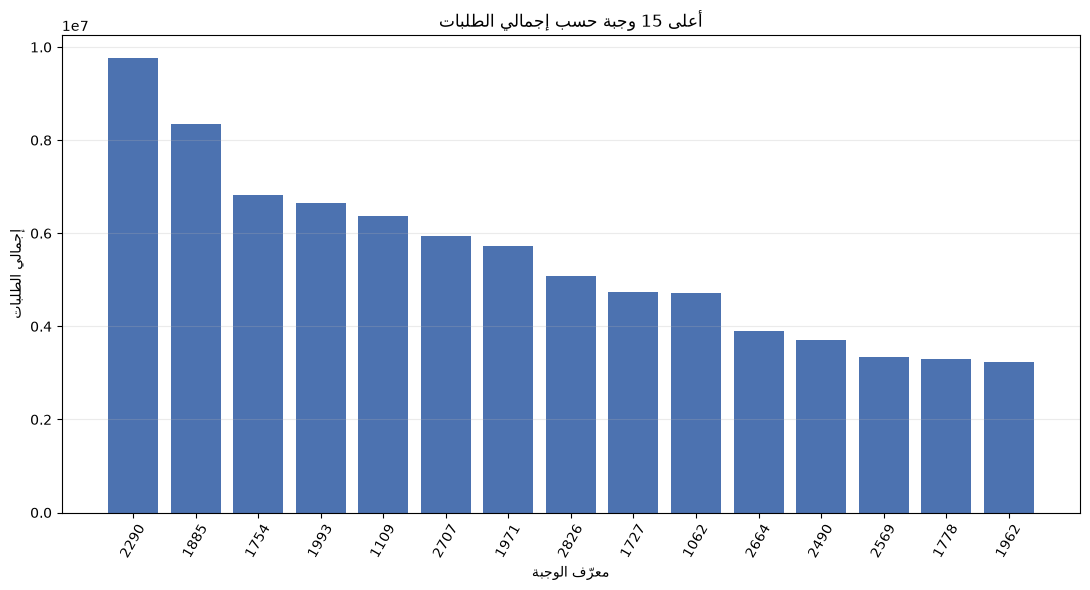

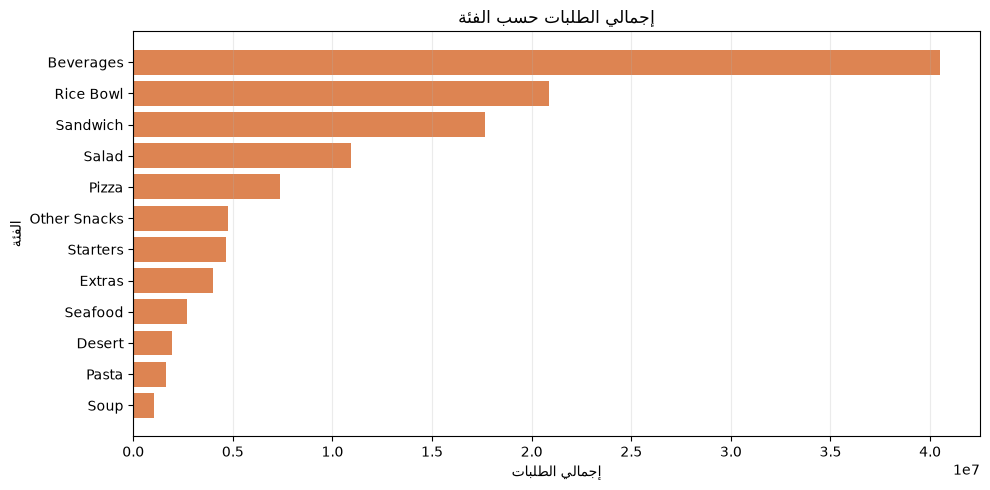

In [24]:
# نعرض أكبر 15 وجبة مع خط الحصة التراكمية للطلب.
top_meals = meal_pareto.head(15).copy()
top_meals["top_cumulative_pct"] = top_meals["share_pct"].cumsum()
fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(top_meals.index.astype(str), top_meals["total_orders"], color="#4C72B0")
ax.set_title("أعلى 15 وجبة حسب إجمالي الطلبات")
ax.set_xlabel("معرّف الوجبة")
ax.set_ylabel("إجمالي الطلبات")
ax.tick_params(axis="x", rotation=60)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

# نعرض أكبر الفئات حسب حصتها من الطلبات.
top_categories = category_pareto.head(12).copy()
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_categories.index.astype(str)[::-1], top_categories["total_orders"].iloc[::-1], color="#DD8452")
ax.set_title("إجمالي الطلبات حسب الفئة")
ax.set_xlabel("إجمالي الطلبات")
ax.set_ylabel("الفئة")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

## 3. مؤشرات الأداء

نحسب إجمالي الطلبات، وقيمة سعرية تقديرية، ومتوسط نسبة الخصم، ونسبة مشاهدات الترويج. يُعرّف وجود الترويج بأنه تفعيل أي من `emailer_for_promotion` أو `homepage_featured`. متوسط الخصم متوسط بسيط على سجلات الطلبات وليس متوسطًا مرجحًا بعدد الطلبات.

In [25]:
# نتحقق من أن السعر الأساسي صالح لحساب نسبة الخصم.
assert (analysis_data["base_price"] > 0).all(), "توجد أسعار أساسية غير موجبة؛ راجع معالجة القيم قبل حساب الخصم"

# نحسب الخصم لكل سجل ونحدد وجود أي ترويج.
analysis_data["discount_pct"] = (
    (analysis_data["base_price"] - analysis_data["checkout_price"])
    / analysis_data["base_price"]
    * 100
)
analysis_data["has_promotion"] = (
    analysis_data["emailer_for_promotion"].eq(1)
    | analysis_data["homepage_featured"].eq(1)
)

# نحسب قيمة سعرية تقريبية دون تسميتها إيرادًا محققًا.
analysis_data["order_price_proxy"] = analysis_data["checkout_price"] * analysis_data["num_orders"]

# نجمع مؤشرات الأداء العامة للفترة كلها.
kpi_summary = pd.Series(
    {
        "إجمالي الطلبات (وحدة طلب)": analysis_data["num_orders"].sum(),
        "قيمة سعرية تقديرية (checkout_price × num_orders)": analysis_data["order_price_proxy"].sum(),
        "متوسط الخصم البسيط (%)": analysis_data["discount_pct"].mean(),
        "نسبة سجلات وجود ترويج (%)": analysis_data["has_promotion"].mean() * 100,
        "عدد سجلات الترويج": analysis_data["has_promotion"].sum(),
        "عدد سجلات البيانات": len(analysis_data),
    },
    name="القيمة",
)

# نعرض المؤشرات مع تنبيه تفسير القيمة السعرية.
print(kpi_summary.to_string())
print("تنبيه: القيمة السعرية التقديرية ليست إيرادًا محققًا؛ لا تتوفر بيانات التحصيل أو التكاليف.")

إجمالي الطلبات (وحدة طلب)                           1.195575e+08
قيمة سعرية تقديرية (checkout_price × num_orders)    3.192277e+10
متوسط الخصم البسيط (%)                              5.719500e+00
نسبة سجلات وجود ترويج (%)                           1.482298e+01
عدد سجلات الترويج                                   6.767400e+04
عدد سجلات البيانات                                  4.565480e+05
تنبيه: القيمة السعرية التقديرية ليست إيرادًا محققًا؛ لا تتوفر بيانات التحصيل أو التكاليف.


## 4. تذبذب الطلب وترتيب الأولوية

يُحسب لكل وجبة معامل الاختلاف `الانحراف المعياري ÷ متوسط الطلب` عبر سجلاتها الأسبوعية/المركزية. يجمع ترتيب الأولوية بين ترتيب حجم الطلب ومتوسط الطلب ومعامل الاختلاف؛ الدرجة الأعلى تعني طلبًا أكبر وتذبذبًا أعلى، وتستحق مراجعة تخطيط المخزون.

In [26]:
# نحسب المتوسط والانحراف المعياري وإجمالي الطلب لكل وجبة.
meal_demand = (
    analysis_data.groupby(["meal_id", "category", "cuisine"], dropna=False)
    .agg(
        total_orders=("num_orders", "sum"),
        mean_orders=("num_orders", "mean"),
        std_orders=("num_orders", "std"),
        observations=("num_orders", "size"),
    )
)

# نحسب معامل الاختلاف مع معالجة الحالات التي متوسطها صفر.
meal_demand["demand_cv"] = meal_demand["std_orders"] / meal_demand["mean_orders"].where(meal_demand["mean_orders"] != 0)

# نحسب مئين ترتيب الحجم والتذبذب لتوحيد مقياس الأولوية.
meal_demand["volume_percentile"] = meal_demand["total_orders"].rank(pct=True)
meal_demand["volatility_percentile"] = meal_demand["demand_cv"].rank(pct=True)
meal_demand["priority_score"] = (
    meal_demand["volume_percentile"] + meal_demand["volatility_percentile"]
) / 2

# نرتب الوجبات حسب الدرجة المشتركة ثم نعرض أعلى الأولويات.
meal_demand = meal_demand.sort_values(
    ["priority_score", "total_orders"], ascending=False
)
print("أعلى 20 وجبة حسب التذبذب وحجم الطلب معًا:")
print(meal_demand.head(20).to_string())

أعلى 20 وجبة حسب التذبذب وحجم الطلب معًا:
                                  total_orders  mean_orders   std_orders  observations  demand_cv  volume_percentile  volatility_percentile  priority_score
meal_id category     cuisine                                                                                                                               
1971    Sandwich     Italian           5728620   515.998919   745.787771         11102   1.445328           0.882353               1.000000        0.941176
2290    Rice Bowl    Indian            9770303   877.204435  1012.412275         11138   1.154135           1.000000               0.862745        0.931373
1754    Sandwich     Italian           6818059   612.473859   716.012427         11132   1.169050           0.960784               0.882353        0.921569
1727    Rice Bowl    Indian            4735987   425.286189   507.470768         11136   1.193245           0.843137               0.901961        0.872549
2490    Salad        I

## 5. مقارنة الطلب مع الترويج وبدونه

لكل وجبة، نقارن `num_orders` بين سجلات وجود أي من الترويجين (`has_promotion`) وسجلات عدم وجودهما، باستخدام Mann–Whitney U ثنائي الطرف. تُحسب قيمة p بتقريب طبيعي مع تصحيح التعادل والاستمرارية؛ وهو مناسب حسابيًا للأعداد الكبيرة لكنه تقريب وليس تنفيذ SciPy. تعرض النتائج بعد تصحيح Holm لتعدد الوجبات.

المشاهدات تتكرر للوجبة نفسها عبر الأسابيع والمراكز، ولذلك لا تحقق استقلالًا كاملًا. تعامل مع الدلالة على أنها استكشافية؛ قد تكون قيم p أصغر من اللازم، والاختبار لا يثبت أثرًا سببيًا.

In [30]:
# نحسب رتبة كل طلب داخل الوجبة مع منح الرتب المتوسطة للتعادلات.
analysis_data["orders_rank_within_meal"] = analysis_data.groupby("meal_id")["num_orders"].rank(method="average")

# نجمع أحجام المجموعتين ومجموع رتب المجموعة المروجة لكل وجبة.
group_stats = (
    analysis_data.groupby(["meal_id", "has_promotion"])
    .agg(
        n=("num_orders", "size"),
        rank_sum=("orders_rank_within_meal", "sum"),
        median_orders=("num_orders", "median"),
    )
    .unstack("has_promotion")
)

# نحتفظ بالوجبات التي لها مشاهدات في المجموعتين فقط.
group_stats.columns = [f"{metric}_{'promoted' if promoted else 'control'}" for metric, promoted in group_stats.columns]
valid_comparison = group_stats.dropna(
    subset=["n_control", "n_promoted", "rank_sum_promoted", "median_orders_control", "median_orders_promoted"]
).copy()
print(f"بعد اختيار الوجبات ذات المجموعتين: الصفوف = {len(valid_comparison):,} | مجموع الطلبات للمجموعتين = {((valid_comparison['median_orders_control'] * valid_comparison['n_control']).sum() + (valid_comparison['median_orders_promoted'] * valid_comparison['n_promoted']).sum()):,.0f} (تقريب تشخيصي بالوسيط)")

# نعد تكرارات قيم الطلب لتصحيح التباين عند وجود رتب متعادلة.
tie_counts = analysis_data.groupby(["meal_id", "num_orders"]).size().rename("tie_n")
tie_term = (tie_counts.pow(3) - tie_counts).groupby(level="meal_id").sum()

# نحسب إحصاء U للمجموعة المروجة من مجموع رتبها.
n0 = valid_comparison["n_control"]
n1 = valid_comparison["n_promoted"]
total_n = n0 + n1
valid_comparison["u_promoted"] = (
    valid_comparison["rank_sum_promoted"] - n1 * (n1 + 1) / 2
)

# نطبق تقريب التوزيع الطبيعي مع تصحيح التعادلات والاستمرارية.
tie_for_meal = tie_term.reindex(valid_comparison.index).fillna(0)
u_mean = n0 * n1 / 2
u_variance = (n0 * n1 / 12) * (
    total_n + 1 - tie_for_meal / (total_n * (total_n - 1))
)
u_delta = valid_comparison["u_promoted"] - u_mean
u_sign = u_delta.gt(0).astype(float) - u_delta.lt(0).astype(float)
valid_comparison["z_score"] = (
    u_delta - 0.5 * u_sign
) / u_variance.pow(0.5)# نحول القيمة المعيارية إلى قيمة p ثنائية الطرف دون استيراد مكتبات إضافية.
def normal_two_sided_p(z_value):
    absolute_z = abs(float(z_value))
    t_value = 1 / (1 + 0.2316419 * absolute_z)
    polynomial = (
        0.319381530 * t_value
        - 0.356563782 * t_value**2
        + 1.781477937 * t_value**3
        - 1.821255978 * t_value**4
        + 1.330274429 * t_value**5
    )
    tail = (2.718281828459045 ** (-0.5 * absolute_z**2))
    tail = tail * polynomial / 2.5066282746310002
    return min(1.0, max(1e-300, 2 * tail))

# نطبق الدالة على الوجبات ونصحح القيم لتعدد الاختبارات بطريقة Holm.
valid_comparison["p_value_approx"] = valid_comparison["z_score"].map(normal_two_sided_p)
valid_comparison = valid_comparison.sort_values("p_value_approx")
valid_comparison["holm_multiplier"] = len(valid_comparison) - pd.RangeIndex(len(valid_comparison))
valid_comparison["p_value_holm"] = (
    valid_comparison["p_value_approx"] * valid_comparison["holm_multiplier"]
).clip(upper=1).cummax()

# نحسب فرق وسيط الطلب بين الترويج وغيابه لكل وجبة.
valid_comparison["median_change_pct"] = (
    (valid_comparison["median_orders_promoted"] - valid_comparison["median_orders_control"])
    / valid_comparison["median_orders_control"].where(valid_comparison["median_orders_control"] != 0)
    * 100
)

# نعرض المقارنات الأكثر دلالة بعد تصحيح Holm.
mw_results = valid_comparison[
    ["n_control", "n_promoted", "median_orders_control", "median_orders_promoted",
     "median_change_pct", "u_promoted", "z_score", "p_value_approx", "p_value_holm"]
]
print(f"عدد الوجبات القابلة للمقارنة = {len(mw_results):,}")
print(mw_results.head(20).to_string())
print(f"عدد الوجبات ذات p-value Holm < 0.05 = {(mw_results['p_value_holm'] < 0.05).sum():,}")

بعد اختيار الوجبات ذات المجموعتين: الصفوف = 51 | مجموع الطلبات للمجموعتين = 97,671,893 (تقريب تشخيصي بالوسيط)
عدد الوجبات القابلة للمقارنة = 51
         n_control  n_promoted  median_orders_control  median_orders_promoted  median_change_pct  u_promoted    z_score  p_value_approx   p_value_holm
meal_id                                                                                                                                               
1207          9177        1629                  121.0                   297.0         145.454545  12475370.5  43.103525   1.000000e-300  5.100000e-299
1230          9137        1609                  122.0                   310.0         154.098361  12134180.5  41.692510   1.000000e-300  5.100000e-299
1558          7284        3668                   81.0                   243.0         200.000000  23180312.0  62.903464   1.000000e-300  5.100000e-299
1445          7579        2148                   53.0                   204.0         284.905660  141

## 6. ارتباط Spearman بين نسبة الخصم والطلب

نحسب ارتباط الرتب بين `discount_pct` و`num_orders` على السجلات ذات القيم المكتملة. قيمة p تقريبية مبنية على التقريب الطبيعي للارتباط عند حجم العينة الكبير. بسبب تكرار الوجبة والمركز عبر الأسابيع، لا تعالج هذه القيمة الترابط داخل المجموعات؛ لذلك تعرض النتيجة كارتباط وصفي لا كأثر سببي.

In [32]:
# نختار عمودي الخصم والطلب اللازمين لحساب الارتباط.
spearman_input = analysis_data[["discount_pct", "num_orders"]].copy()

# نستبعد القيم غير المكتملة ونطبع عدد الصفوف ومجموع الطلبات بعد التصفية.
spearman_data = spearman_input.dropna().copy()
print(f"بعد تصفية القيم المكتملة لارتباط Spearman: الصفوف = {len(spearman_data):,} | مجموع num_orders = {spearman_data['num_orders'].sum():,.0f}")

# نحسب رتبة الخصم والطلب، مع استخدام متوسط الرتب للقيم المتعادلة.
discount_ranks = spearman_data["discount_pct"].rank(method="average")
order_ranks = spearman_data["num_orders"].rank(method="average")

# نحسب ارتباط بيرسون بين الرتب للحصول على معامل Spearman دون SciPy.
spearman_rho = discount_ranks.corr(order_ranks, method="pearson")
spearman_n = len(spearman_data)
spearman_z = spearman_rho * (spearman_n - 1) ** 0.5
spearman_p_approx = normal_two_sided_p(spearman_z)

# نعرض معامل الارتباط وحجم العينة وقيمة p التقريبية.
print(f"Spearman rho = {spearman_rho:.4f}")
print(f"حجم العينة = {spearman_n:,}")
print(f"قيمة p تقريبية ثنائية الطرف = {spearman_p_approx:.3g}")
print("التفسير: الارتباط يصف الترافق بين الخصم والطلب ولا يثبت السببية؛ قيمة p لا تصحح اعتماد السجلات المتكررة.")

بعد تصفية القيم المكتملة لارتباط Spearman: الصفوف = 456,548 | مجموع num_orders = 119,557,485
Spearman rho = 0.1218
حجم العينة = 456,548
قيمة p تقريبية ثنائية الطرف = 1e-300
التفسير: الارتباط يصف الترافق بين الخصم والطلب ولا يثبت السببية؛ قيمة p لا تصحح اعتماد السجلات المتكررة.


## 7. قراءة النتائج وحدودها

- استخدم جداول باريتو لتحديد الوجبات والفئات والمراكز الأعلى مساهمة في الطلب، مع عدم الخلط بين حصة الطلب وحصة الربح.
- قيمة `order_price_proxy` تقريب حسابي بسعر `checkout_price` المسجل مضروبًا في `num_orders`؛ ليست إيرادًا فعليًا أو صافيًا، ولا تشمل التكاليف أو التحصيل.
- `discount_pct` قد يكون سالبًا عندما يتجاوز `checkout_price` السعر `base_price`؛ أبقينا هذه الحالات كما هي حسب قرارات التنظيف السابقة، ويجب تفسيرها قبل استنتاج أثر الخصم.
- معاملات التذبذب ودرجات الأولوية أدوات فرز للمراجعة، وليست حدود مخزون جاهزة. ينبغي ربطها بمهلة التوريد ومستوى الخدمة والهدر قبل اعتماد كميات أمان.
- Mann–Whitney وSpearman هنا استكشافيان. تكرار القياس حسب الوجبة والمركز والأسبوع يضعف افتراض استقلال المشاهدات، كما قد تختلف الأسعار والموسمية واختيار العروض بين المجموعات.
- لا توسّع العروض اعتمادًا على الدلالة الإحصائية وحدها؛ يلزم تقدير أثر مضبوط للتكلفة وهوامش الربح، ويفضل اختبار تجريبي أو نموذج يراعي المركز والوجبة والزمن.

## 8. الرسوم البيانية الرئيسية

ترسم الخلايا التالية الطلب الأسبوعي، والطلب حسب الفئة، وتوزيعات الطلب بحسب وجود الترويج، والعلاقة بين الخصم والطلب. تحفظ الرسوم تلقائيًا في `reports/figures/` مع عرضها داخل الدفتر. تُعرّف سجلات الترويج بوجود `emailer_for_promotion` أو `homepage_featured`.

بيانات الرسوم: الصفوف = 456,548 | مجموع num_orders = 119,557,485
تم حفظ الرسم: e:\food-demand-analysis\reports\figures\weekly_orders.png


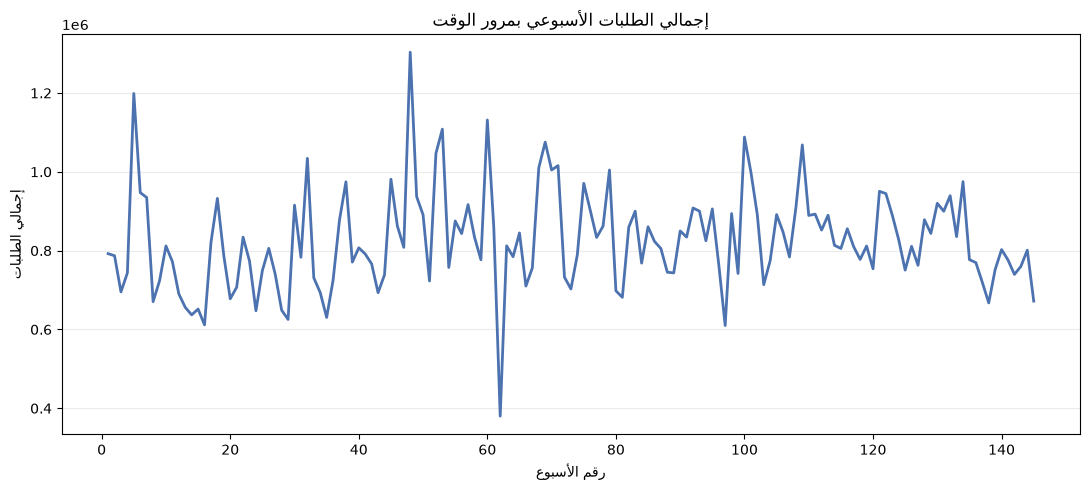

تم حفظ الرسم: e:\food-demand-analysis\reports\figures\orders_by_category.png


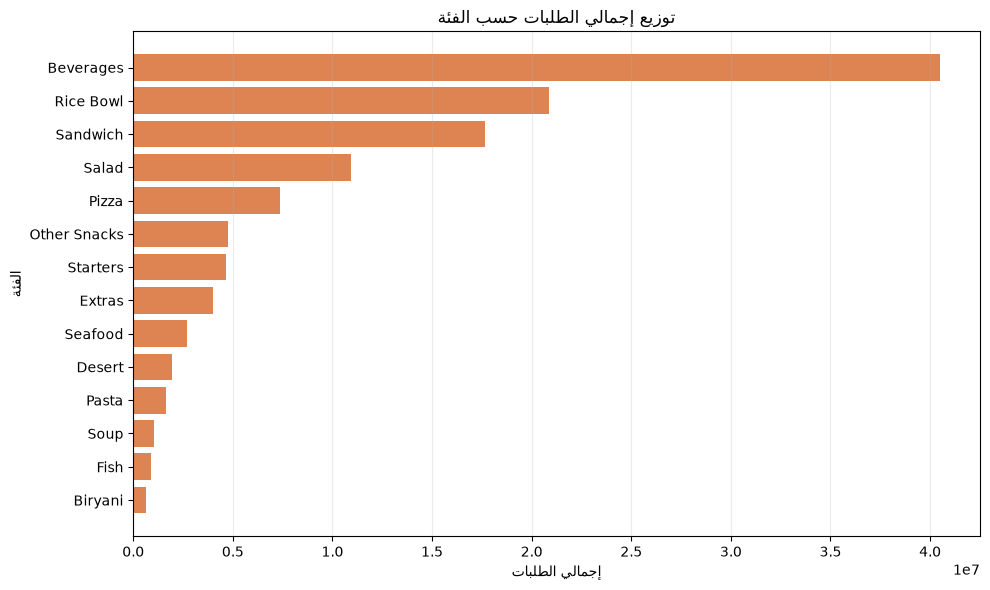

بعد تصفية سجلات دون ترويج: الصفوف = 388,874 | مجموع num_orders = 82,214,568
بعد تصفية سجلات مع ترويج: الصفوف = 67,674 | مجموع num_orders = 37,342,917
تم حفظ الرسم: e:\food-demand-analysis\reports\figures\orders_promotion_boxplot.png


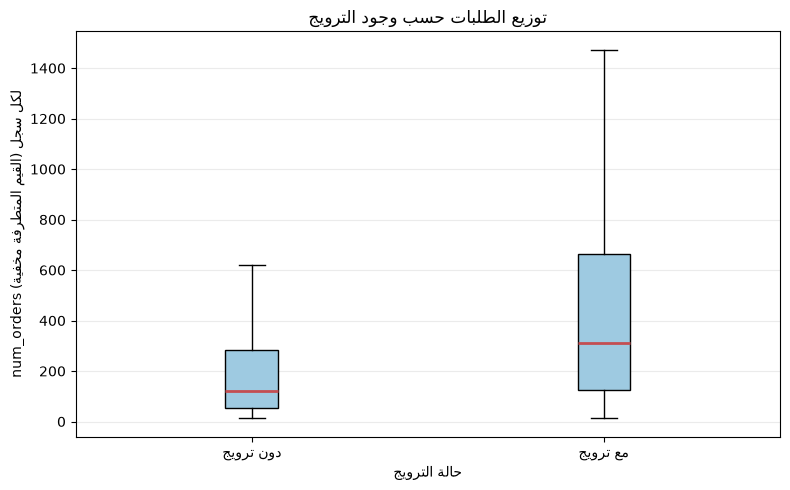

تم حفظ الرسم: e:\food-demand-analysis\reports\figures\discount_vs_orders_scatter.png


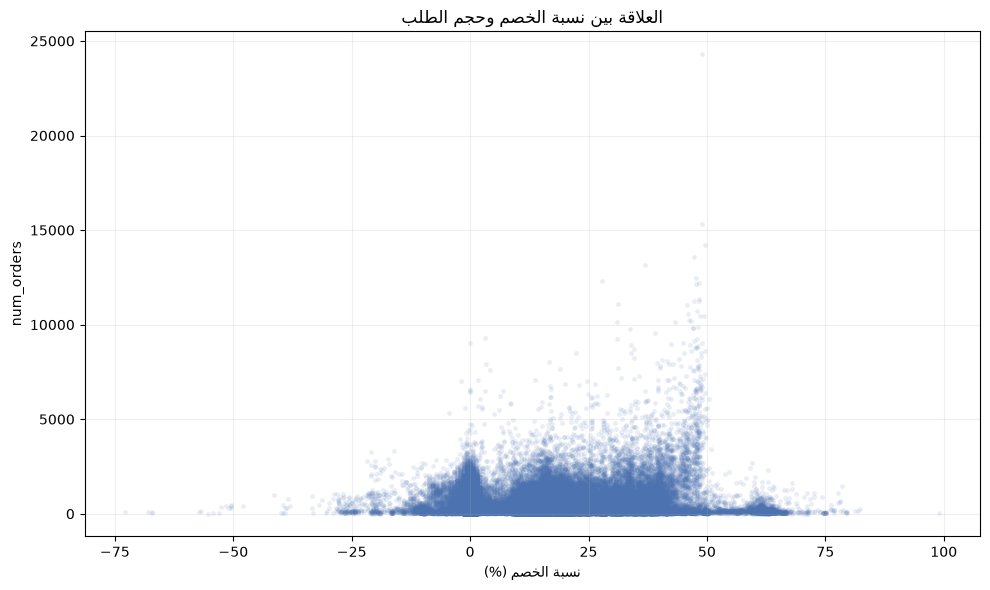

In [33]:
from pathlib import Path

# نتحقق من اكتمال الحقول المستخدمة في الرسوم.
plot_columns = ["week", "category", "num_orders", "has_promotion", "discount_pct"]
assert analysis_data[plot_columns].notna().all().all(), "توجد قيم ناقصة في أعمدة الرسم؛ راجع الجودة قبل الرسم"
print(f"بيانات الرسوم: الصفوف = {len(analysis_data):,} | مجموع num_orders = {analysis_data['num_orders'].sum():,.0f}")

# نحدد مجلد المشروع ومكان حفظ ملفات PNG.
project_root = Path.cwd()
if not (project_root / "data" / "dataraw" / "train.csv").exists():
    project_root = project_root.parent
figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# نجمع الطلبات حسب الأسبوع لعرض اتجاهها الزمني.
weekly_orders = (
    analysis_data.groupby("week", as_index=False)["num_orders"]
    .sum()
    .sort_values("week")
)
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(weekly_orders["week"], weekly_orders["num_orders"], color="#4C72B0", linewidth=2)
ax.set_title("إجمالي الطلبات الأسبوعي بمرور الوقت")
ax.set_xlabel("رقم الأسبوع")
ax.set_ylabel("إجمالي الطلبات")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(figures_dir / "weekly_orders.png", dpi=160, bbox_inches="tight")
print(f"تم حفظ الرسم: {figures_dir / 'weekly_orders.png'}")
plt.show()
plt.close(fig)

# نرتب الفئات حسب إجمالي الطلبات لتسهيل المقارنة.
category_orders = (
    analysis_data.groupby("category", as_index=False)["num_orders"]
    .sum()
    .sort_values("num_orders", ascending=True)
)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(category_orders["category"], category_orders["num_orders"], color="#DD8452")
ax.set_title("توزيع إجمالي الطلبات حسب الفئة")
ax.set_xlabel("إجمالي الطلبات")
ax.set_ylabel("الفئة")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(figures_dir / "orders_by_category.png", dpi=160, bbox_inches="tight")
print(f"تم حفظ الرسم: {figures_dir / 'orders_by_category.png'}")
plt.show()
plt.close(fig)

# نجهز مجموعتي الطلب ونطبع إحصاء كل مجموعة بعد التصفية.
no_promotion_orders = analysis_data.loc[~analysis_data["has_promotion"], "num_orders"]
print(f"بعد تصفية سجلات دون ترويج: الصفوف = {len(no_promotion_orders):,} | مجموع num_orders = {no_promotion_orders.sum():,.0f}")
promotion_orders = analysis_data.loc[analysis_data["has_promotion"], "num_orders"]
print(f"بعد تصفية سجلات مع ترويج: الصفوف = {len(promotion_orders):,} | مجموع num_orders = {promotion_orders.sum():,.0f}")
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(
    [no_promotion_orders, promotion_orders],
    tick_labels=["دون ترويج", "مع ترويج"],
    showfliers=False,
    patch_artist=True,
    boxprops={"facecolor": "#9ECAE1"},
    medianprops={"color": "#C44E52", "linewidth": 2},
)
ax.set_title("توزيع الطلبات حسب وجود الترويج")
ax.set_xlabel("حالة الترويج")
ax.set_ylabel("num_orders لكل سجل (القيم المتطرفة مخفية)")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(figures_dir / "orders_promotion_boxplot.png", dpi=160, bbox_inches="tight")
print(f"تم حفظ الرسم: {figures_dir / 'orders_promotion_boxplot.png'}")
plt.show()
plt.close(fig)

# نرسم جميع السجلات لإظهار العلاقة الوصفية بين الخصم والطلب.
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(
    analysis_data["discount_pct"],
    analysis_data["num_orders"],
    color="#4C72B0",
    alpha=0.12,
    s=12,
    linewidths=0,
    rasterized=True,
)
ax.set_title("العلاقة بين نسبة الخصم وحجم الطلب")
ax.set_xlabel("نسبة الخصم (%)")
ax.set_ylabel("num_orders")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(figures_dir / "discount_vs_orders_scatter.png", dpi=160, bbox_inches="tight")
print(f"تم حفظ الرسم: {figures_dir / 'discount_vs_orders_scatter.png'}")
plt.show()
plt.close(fig)